# EDA: данные ReqAssist

Цель - оценить состав, объём и качество данных, на которых будет строиться и оцениваться валидация БТ (задача A дизайн-документа), и набор атак для защиты от prompt injection (задача D).

**Источники** (лежат в рабочем репозитории продукта, в этот репозиторий не копируются):

| Данные | Что это | Объём |
| --- | --- | --- |
| Документы Confluence | HTML-экспорт реальных страниц БТ и ФТ | 6 документов |
| Чеклист | стандартный чеклист качества БТ, markdown | 1 файл |
| Набор атак | payload-ы prompt injection и легитимные тексты для тестового стенда | 30 текстов |
| Результаты прогона атак | ответы стенда на первом этапе защиты, JSON | 18 запусков |
| Eval-кейсы | кейсы с ожидаемым диапазоном ответа | 5 кейсов |

**Конфиденциальность.** Документы - внутренние. В выводах ноутбука только агрегаты: документы называются `doc_01`..`doc_06`, названия страниц, текст и номера задач не печатаются. Примеры структуры показаны после маскирования (`reqassist.data.anonymize`). Названия пунктов чеклиста не выводятся: в их описаниях есть ФИО сотрудников.

Путь к данным задаётся переменной окружения `REQASSIST_DIR` (по умолчанию соседняя папка `ReqAssist`).

In [1]:
import json
import os
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from reqassist.data.anonymize import mask
from reqassist.data.checklist import parse_checklist
from reqassist.data.confluence import load_documents
from reqassist.data.injection import l1_matches, parse_payloads
from reqassist.data.sections import canonical_section

DATA = Path(os.environ.get("REQASSIST_DIR", "../../ReqAssist")).resolve()
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# грубая оценка токенов для русского текста: около 4 символов на токен
CHARS_PER_TOKEN = 4
PARALLEL_THRESHOLD = 15_000  # порог разбиения чеклиста на 3 вызова в продукте


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

## 1. Состав и объём документов

In [2]:
docs = load_documents(DATA / "test-fixtures/br-documents")


def table_text_chars(doc):
    return sum(len(s.text) for s in doc.sections if s.tables)


overview = pd.DataFrame(
    {
        "doc": d.doc_id,
        "тип": d.kind,
        "HTML страницы, тыс. симв.": d.raw_chars / 1000,
        "HTML контента, тыс. симв.": d.content_html_chars / 1000,
        "текст, тыс. симв.": len(d.text) / 1000,
        "слов": len(d.text.split()),
        "токенов (оценка), тыс.": len(d.text) / CHARS_PER_TOKEN / 1000,
        "разделов": len(d.sections),
        "таблиц": d.tag_counts.get("table", 0),
        "изображений": d.tag_counts.get("img", 0),
    }
    for d in docs
).set_index("doc")
overview

,тип,"HTML страницы, тыс. симв.","HTML контента, тыс. симв.","текст, тыс. симв.",слов,"токенов (оценка), тыс.",разделов,таблиц,изображений
doc,,,,,,,,,
doc_01,BT,186.02,61.22,21.08,2932,5.27,12,6,5
doc_02,BT,79.42,21.92,7.48,1044,1.87,8,4,3
doc_03,BT,43.46,9.59,4.11,604,1.03,5,1,1
doc_04,BT,31.70,6.55,2.38,344,0.60,7,1,3
doc_05,BT,135.21,45.72,13.92,1809,3.48,13,17,5
doc_06,FT,36.28,16.73,3.39,381,0.85,3,1,1


In [3]:
overview[["тип", "текст, тыс. симв.", "слов", "разделов", "таблиц", "изображений"]].describe()

,"текст, тыс. симв.",слов,разделов,таблиц,изображений
count,6.00,6.00,6.0,6.00,6.00
mean,8.73,1185.67,8.0,5.00,3.00
std,7.36,1015.14,3.9,6.23,1.79
min,2.38,344.00,3.0,1.00,1.00
25%,3.57,436.75,5.5,1.00,1.50
50%,5.79,824.00,7.5,2.50,3.00
75%,12.31,1617.75,11.0,5.50,4.50
max,21.08,2932.00,13.0,17.00,5.00


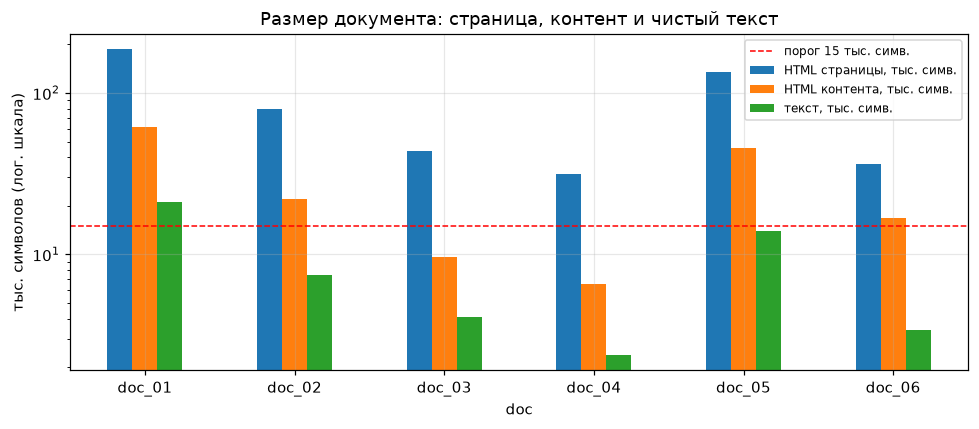

In [4]:
ax = overview[
    ["HTML страницы, тыс. симв.", "HTML контента, тыс. симв.", "текст, тыс. симв."]
].plot.bar(figsize=(9, 4), logy=True, rot=0)
ax.axhline(PARALLEL_THRESHOLD / 1000, color="red", ls="--", lw=1, label="порог 15 тыс. симв.")
ax.set_ylabel("тыс. символов (лог. шкала)")
ax.set_title("Размер документа: страница, контент и чистый текст")
ax.legend(fontsize=8)
savefig("01_doc_sizes")

**Выводы.**

- Выборка очень маленькая: 6 документов, из них 5 БТ и 1 ФТ. Статистики ниже описывают именно эту выборку и не переносятся на весь поток БТ без проверки.
- Документы взяты из тестовых примеров продукта, а не случайно: их могли отбирать как показательные или трудные. Это возможное смещение выборки; на расширенной выборке (этап 1 дизайн-документа) документы выгружаются подряд за период.
- Документы сильно различаются по размеру: чистый текст от ~2 до ~21 тыс. символов (на порядок), это от ~500 до ~5 тыс. токенов. Все документы целиком помещаются в контекст модели; узкое место не в тексте БТ, а в разметке (см. раздел 2).
- В документах много таблиц и изображений. Изображения (схемы процессов, скриншоты UI) текстовая модель не видит - часть содержания БТ для неё недоступна.

## 2. Шум разметки и порог распараллеливания

In [5]:
noise = pd.DataFrame(
    {
        "doc": d.doc_id,
        "доля текста в HTML страницы, %": 100 * len(d.text) / d.raw_chars,
        "доля текста в HTML контента, %": 100 * len(d.text) / d.content_html_chars,
        "span": d.tag_counts.get("span", 0),
        "HTML контента > 15K": d.content_html_chars > PARALLEL_THRESHOLD,
        "текст > 15K": len(d.text) > PARALLEL_THRESHOLD,
    }
    for d in docs
).set_index("doc")
noise

,"доля текста в HTML страницы, %","доля текста в HTML контента, %",span,HTML контента > 15K,текст > 15K
doc,,,,,
doc_01,11.33,34.44,220,True,True
doc_02,9.42,34.12,36,True,False
doc_03,9.46,42.85,21,False,False
doc_04,7.52,36.37,14,False,False
doc_05,10.29,30.44,140,True,False
doc_06,9.34,20.27,114,True,False


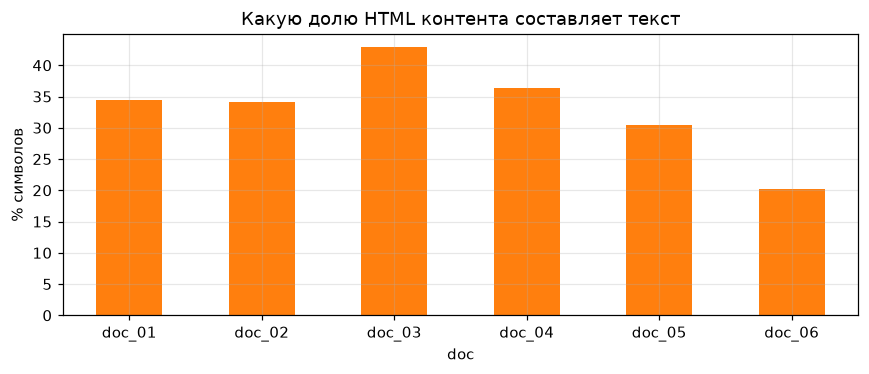

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
noise["доля текста в HTML контента, %"].plot.bar(ax=ax, rot=0, color="tab:orange")
ax.set_ylabel("% символов")
ax.set_title("Какую долю HTML контента составляет текст")
savefig("02_text_share")

**Выводы.**

- Текст - всего 20-43% HTML-контента страницы и 8-11% полного экспорта. Остальное - теги, стили, `span`, служебные атрибуты Confluence. Модель тратит на них большую часть токенов, а на качество проверки они не влияют.
- Порог распараллеливания в продукте (15 тыс. символов) сравнивается с длиной HTML. По HTML порог превышают 4 документа из 6, по чистому тексту - только 1. То есть разбиение на 3 вызова (и тройной расход токенов) сейчас чаще срабатывает из-за разметки, а не из-за объёма содержания.
- Следствие для этапа подготовки данных: нормализация HTML перед вызовом модели (убрать стили, `span`, пустые элементы). Решение о разбиении на 3 вызова не должно зависеть от длины HTML: разбиение нужно ради скорости ответа (раздел 9), а не из-за размера документа.
- Допущение: здесь измерен HTML-экспорт страницы (блок `#main-content`). В модель уходит HTML из API Confluence (`body.view`); он близок по составу, но может отличаться по длине. Вывод про порог нужно подтвердить на нескольких документах, выгруженных через API, - это первая проверка этапа 1.

## 3. Структура документов

In [7]:
levels = pd.DataFrame(
    {
        "doc": d.doc_id,
        "уровень разделов верхнего уровня": f"h{d.top_level}",
        "разделов верхнего уровня": len(d.top_sections),
        "уровни заголовков в документе": " ".join(sorted({f"h{s.level}" for s in d.sections})),
    }
    for d in docs
).set_index("doc")
levels

,уровень разделов верхнего уровня,разделов верхнего уровня,уровни заголовков в документе
doc,,,
doc_01,h2,7,h2 h3 h4
doc_02,h1,6,h1 h2
doc_03,h4,5,h4
doc_04,h1,6,h1 h2
doc_05,h1,7,h1 h2
doc_06,h2,1,h2 h3 h4


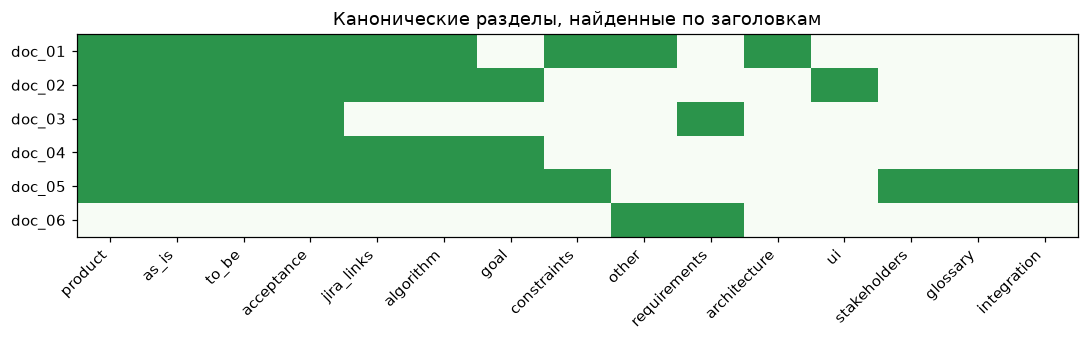

,product,as_is,to_be,acceptance,jira_links,algorithm,goal,constraints,other,requirements,architecture,ui,stakeholders,glossary,integration
документов с разделом,5,5,5,5,4,4,3,2,2,2,1,1,1,1,1


In [8]:
presence = (
    pd.DataFrame(
        [{canonical_section(s.title): 1 for s in d.sections} | {"doc": d.doc_id} for d in docs]
    )
    .set_index("doc")
    .fillna(0)
    .astype(int)
)
order = presence.sum().sort_values(ascending=False).index
presence = presence[order]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow(presence.values, cmap="Greens", aspect="auto", vmin=0, vmax=1.4)
ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
ax.set_yticks(range(len(presence)), presence.index)
ax.grid(False)
ax.set_title("Канонические разделы, найденные по заголовкам")
savefig("03_sections_heatmap")
presence.sum().to_frame("документов с разделом").T

Пример структуры одного БТ после маскирования (названия продуктов, номера и аббревиатуры заменены):

In [9]:
example = docs[1]
for s in example.sections:
    print(
        "  " * (s.level - example.top_level)
        + f"h{s.level}: {mask(s.title)}  [{canonical_section(s.title)}]"
    )

h1: <abbr> задачи в <abbr>  [jira_links]
h1: Продукт  [product]
h1: Цель доработки  [goal]
h1: Процесс <abbr> <abbr>  [as_is]
h1: Процесс <abbr> <abbr>  [to_be]
  h2: Доработка <abbr>  [ui]
  h2: Алгоритм расчета  [algorithm]
h1: Критерии приемки  [acceptance]


**Выводы.**

- Структура БТ устоявшаяся: «Продукт», «Процесс AS IS», «Процесс TO BE» и «Критерии приёмки» есть во всех 5 БТ, ссылки на задачи Jira - в 4 из 5. ФТ устроен иначе и почти не делится на разделы.
- Уровень заголовков не стандартизирован: разделы верхнего уровня оформлены как `h1`, `h2` или `h4` в зависимости от документа. Логика вставки правок не может полагаться на конкретный уровень - его нужно определять по документу (минимальный уровень заголовков в контенте).
- Нумерация разделов есть не везде («1. ID фичи в JIRA» и «ID задачи в JIRA») - при сопоставлении заголовков нумерацию нужно отбрасывать.
- Разделы, которые проверяет значимая часть чеклиста (данные К/И, заинтересованные лица, тестовые сценарии, интеграции), отдельными заголовками почти не встречаются: если сведения и есть, то внутри «TO BE» или таблиц.

## 4. Содержимое разделов

In [10]:
sec = pd.DataFrame(
    {
        "doc": d.doc_id,
        "раздел": canonical_section(s.title),
        "символов": len(s.text),
        "таблиц": s.tables,
        "изображений": s.images,
        "пустой": s.is_empty,
    }
    for d in docs
    for s in d.sections
)
summary = sec.groupby("doc").agg(
    разделов=("раздел", "size"),
    пустых=("пустой", "sum"),
    медиана_символов=("символов", "median"),
    разделов_с_таблицами=("таблиц", lambda x: int((x > 0).sum())),
)
summary["доля текста в разделах с таблицами, %"] = [
    100 * table_text_chars(d) / max(len(d.text), 1) for d in docs
]
summary

,разделов,пустых,медиана_символов,разделов_с_таблицами,"доля текста в разделах с таблицами, %"
doc,,,,,
doc_01,12,0,992.0,5,76.76
doc_02,8,0,650.0,3,56.92
doc_03,5,1,323.0,1,25.72
doc_04,7,0,255.0,1,11.25
doc_05,13,1,635.0,10,95.49
doc_06,3,0,149.0,1,87.91


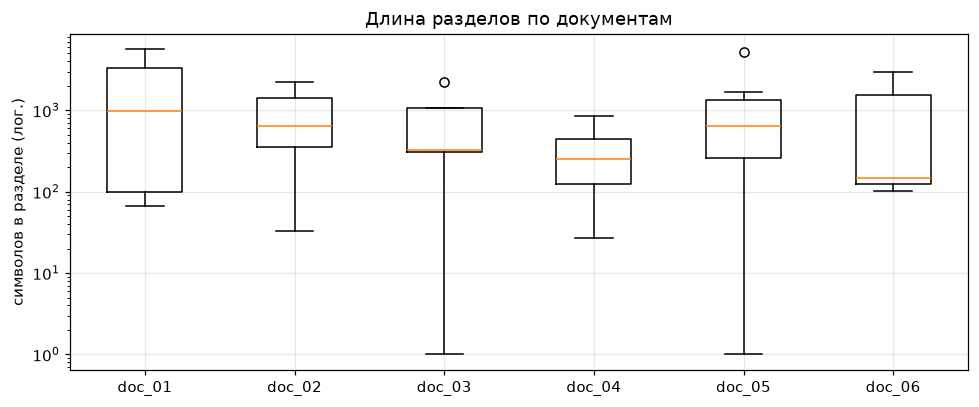

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
data = [sec.loc[sec["doc"] == d.doc_id, "символов"].clip(lower=1) for d in docs]
ax.boxplot(data, tick_labels=[d.doc_id for d in docs])
ax.set_yscale("log")
ax.set_ylabel("символов в разделе (лог.)")
ax.set_title("Длина разделов по документам")
savefig("04_section_lengths")

**Выводы.**

- Длина разделов различается на 2-3 порядка: от одной строки («Продукт») до нескольких тысяч символов («TO BE» с алгоритмами расчёта). Основное содержание сосредоточено в 1-2 разделах.
- Пустых разделов или заглушек мало (2 на 6 документов): БТ в выборке - согласованные документы, а не черновики. Для оценки статусов `missing` и `partial_placeholder` нужны черновики или искусственно испорченные копии документов.
- В 4 из 6 документов больше половины текста приходится на разделы с таблицами (до 95%): формулы, справочники, параметры расчёта оформлены таблицами. Нормализация не должна терять табличную структуру: при «расплющивании» таблицы в текст теряется связь заголовка столбца со значением.

## 5. Чеклист

In [12]:
items = parse_checklist(DATA / "public/checklists/v1.md")
checklist = pd.DataFrame(
    {"id": i.item_id, "раздел": f"{i.section_no}. {i.section}", "проверяется по": i.source}
    for i in items
)
print("пунктов:", len(checklist), "| разделов:", checklist["раздел"].nunique())
print("повторяющиеся id:", [k for k, v in Counter(checklist["id"]).items() if v > 1])
pd.crosstab(checklist["раздел"], checklist["проверяется по"], margins=True, margins_name="всего")

пунктов: 39 | разделов: 6
повторяющиеся id: ['5.4']


проверяется по,bt_text,ft_text,linked_doc,process,всего
раздел,,,,,
1. Взятие задачи в работу,0,0,1,4,5
2. Составить RoadMap по доработке,4,0,0,2,6
3. Написание БТ,8,0,1,3,12
4. Архитектура (опционально),1,0,0,2,3
5. Написание ФТ,0,9,0,0,9
6. Специальные проверки,4,0,0,0,4
всего,17,9,2,11,39


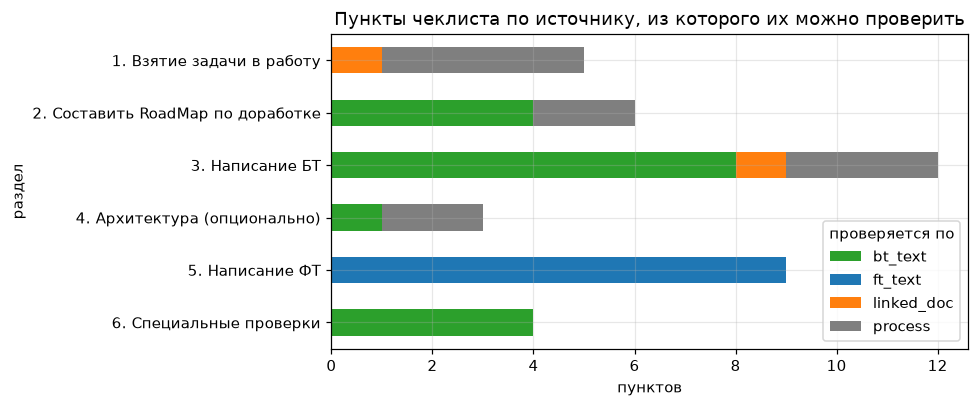

In [13]:
ct = pd.crosstab(checklist["раздел"], checklist["проверяется по"])
ct = ct[[c for c in ["bt_text", "ft_text", "linked_doc", "process"] if c in ct]]
ax = ct.plot.barh(
    stacked=True, figsize=(9, 3.8), color=["tab:green", "tab:blue", "tab:orange", "tab:gray"]
)
ax.invert_yaxis()
ax.set_xlabel("пунктов")
ax.set_title("Пункты чеклиста по источнику, из которого их можно проверить")
savefig("05_checklist_sources")

Разметку источника сделал DS по описаниям пунктов, затем её подтвердил аналитик. Значения: `bt_text` - проверяется по тексту БТ, `ft_text` - по тексту ФТ, `linked_doc` - нужен связанный документ (CR), `process` - это действие в процессе (создать эпик, пройти ревью, получить согласование), и в тексте документа его не видно.

**Выводы.**

- В чеклисте 39 пунктов в 6 разделах, а не около 30, как предполагалось. У двух разных пунктов одинаковый номер `5.4` - модель использует номер как `item_id`, и ответы по этим пунктам будут склеиваться при слиянии. Номера нужно сделать уникальными.
- Только 17 из 39 пунктов (44%) можно проверить по тексту БТ. 11 пунктов - действия процесса, 2 требуют связанного CR, 9 относятся к ФТ. Для БТ корректный ответ по 22 пунктам - `not_applicable` или «нельзя проверить по документу». Если модель этого не различает, она либо галлюцинирует выполнение, либо занижает скор.
- Целевую переменную задачи A нужно уточнить: оценивать скор только по проверяемым пунктам, а процессные пункты показывать отдельным списком «проверьте вручную».

## 6. Бейзлайн B1 на реальных БТ

B1 (`reqassist.baseline`) проверяет пункты чеклиста по заголовкам: 6 из 17 проверяемых по тексту БТ пунктов привязаны к типу раздела, для них статус определяется по наличию и заполненности раздела; остальные 11 правила проверить не могут и получают `missing`. Скор считается по формуле из дизайн-документа (2.1).

Все 5 БТ выборки - согласованные документы, то есть эксперт считал их достаточно полными. Высокий скор правила должны были бы поставить и им.

In [14]:
from reqassist.baseline import ITEM_TO_SECTION, run_b1

bt_docs = [d for d in docs if d.kind == "BT"]
b1 = [run_b1(d, items) for d in bt_docs]
mappable = list(ITEM_TO_SECTION)
b1_table = pd.DataFrame(
    {
        "doc": r.doc_id,
        "completed": sum(s == "completed" for s in r.statuses.values()),
        "partial_placeholder": sum(s == "partial_placeholder" for s in r.statuses.values()),
        "missing": sum(s == "missing" for s in r.statuses.values()),
        "скор по 17 пунктам": r.score(),
        "скор по 6 привязываемым": r.score(mappable),
    }
    for r in b1
).set_index("doc")
b1_table

,completed,partial_placeholder,missing,скор по 17 пунктам,скор по 6 привязываемым
doc,,,,,
doc_01,2,0,15,12,33
doc_02,1,0,16,6,17
doc_03,0,1,16,1,2
doc_04,1,0,16,6,17
doc_05,3,0,14,18,50


In [15]:
status_matrix = pd.DataFrame({r.doc_id: r.statuses for r in b1}).T[mappable]
print("статусы B1 по привязываемым пунктам:")
status_matrix

статусы B1 по привязываемым пунктам:


,3.3,3.4,3.6,3.10,4.1,6.1
doc_01,missing,missing,completed,missing,completed,missing
doc_02,missing,missing,completed,missing,missing,missing
doc_03,missing,missing,partial_placeholder,missing,missing,missing
doc_04,missing,missing,completed,missing,missing,missing
doc_05,completed,missing,completed,missing,missing,completed


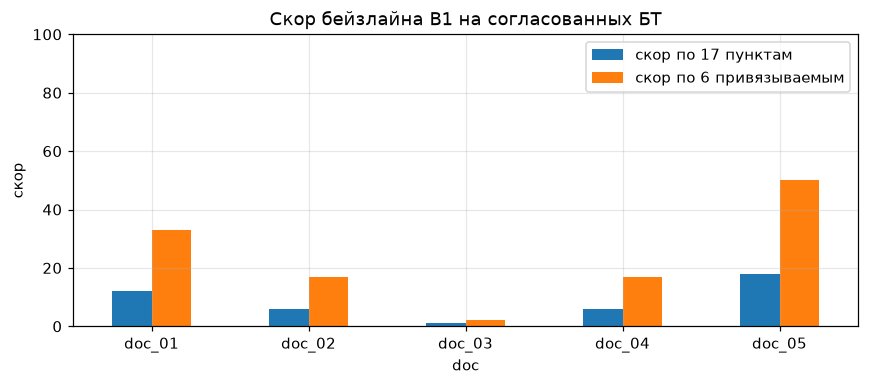

In [16]:
ax = b1_table[["скор по 17 пунктам", "скор по 6 привязываемым"]].plot.bar(figsize=(8, 3.6), rot=0)
ax.set_ylim(0, 100)
ax.set_ylabel("скор")
ax.set_title("Скор бейзлайна B1 на согласованных БТ")
savefig("06_baseline_b1")

**Выводы.**

- B1 ставит согласованным БТ скор 1-18 из 100: правила находят 1-3 раздела на документ, и почти всегда это «Продукт». Даже на 6 пунктах, к которым правила применимы, скор не выше 50.
- Пункты про данные К/И, тестовые сценарии, интеграции и заинтересованных лиц в выборке почти не оформлены отдельными разделами, хотя сведения могут быть внутри «TO BE» и таблиц. Правила по заголовкам систематически занижают полноту.
- Словарь разделов и привязка пунктов составлены по этим же 6 документам, то есть правила подогнаны под выборку. Значит, на новых документах B1 будет работать не лучше, а скорее хуже, и вывод о его слабости только усиливается.
- Без разметки нельзя посчитать F1, но уже видно: B1 не различает полный и неполный документ и годится только как нижняя граница. Это количественный аргумент в пользу LLM для MVP.

## 7. Набор атак prompt injection

In [17]:
payloads = parse_payloads(DATA / "back/routes/securityTest.js")


def script(text):
    cyr = len(re.findall(r"[а-яё]", text, re.IGNORECASE))
    lat = len(re.findall(r"[a-z]", text, re.IGNORECASE))
    return "кириллица" if cyr > lat else "латиница"


pl = pd.DataFrame(
    {
        "id": p.payload_id,
        "категория": p.category,
        "атака": p.is_attack,
        "символов": len(p.text),
        "язык": script(p.text),
        "ловит L1": bool(l1_matches(p.text)),
    }
    for p in payloads
)
pd.crosstab(pl["категория"], pl["ловит L1"], margins=True, margins_name="всего")

ловит L1,False,True,всего
категория,,,
baseline,5,0,5
bypass,5,0,5
exact,0,8,8
obfuscation,5,0,5
semantic,5,2,7
всего,20,10,30


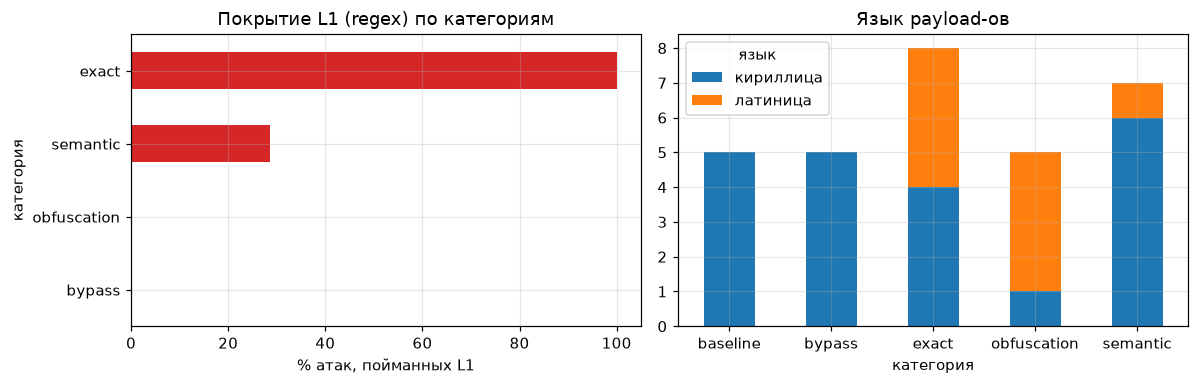

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
l1 = pl[pl["атака"]].groupby("категория")["ловит L1"].mean().mul(100).sort_values()
l1.plot.barh(ax=axes[0], color="tab:red")
axes[0].set_xlabel("% атак, пойманных L1")
axes[0].set_title("Покрытие L1 (regex) по категориям")
pd.crosstab(pl["категория"], pl["язык"]).plot.bar(ax=axes[1], stacked=True, rot=0)
axes[1].set_title("Язык payload-ов")
savefig("07_injection_set")

In [19]:
fp_docs = {d.doc_id: l1_matches(d.text) for d in docs}
print(
    "срабатываний L1 на реальных документах:",
    sum(bool(v) for v in fp_docs.values()),
    "из",
    len(docs),
)
print("длина payload-ов, символов:", pl["символов"].describe()[["min", "50%", "max"]].to_dict())

срабатываний L1 на реальных документах: 0 из 6
длина payload-ов, символов: {'min': 62.0, '50%': 99.0, 'max': 231.0}


In [20]:
runs = json.loads(
    (DATA / "scripts/security/results-2026-06-09-13-33-27.json").read_text(encoding="utf-8")
)
res = pd.DataFrame(
    {
        "категория": r["category"],
        "L1 сработал": r["meta"]["injectionDetected"],
        "утечка canary": r["meta"]["canaryLeaked"],
        "время, с": r["durationMs"] / 1000,
        "токенов ответа": r["meta"].get("gigachatTokens"),
    }
    for r in runs
)
res.groupby("категория").agg(
    запусков=("L1 сработал", "size"),
    L1=("L1 сработал", "sum"),
    утечек=("утечка canary", "sum"),
    медиана_времени_с=("время, с", "median"),
    макс_времени_с=("время, с", "max"),
)

,запусков,L1,утечек,медиана_времени_с,макс_времени_с
категория,,,,,
baseline,3,0,0,180.01,180.01
exact,8,8,0,25.55,180.01
semantic,7,0,0,16.62,55.00


**Выводы.**

- Набор сбалансирован по категориям (8 точных, 7 семантических, 5 обфусцированных, 5 обходов, 5 легитимных), но мал: 25 атак и 5 негативов. Оценка FPR на 5 коротких негативах ненадёжна. Реальные БТ - лучший источник негативов: на всех 6 документах L1 не сработал ни разу.
- L1 ловит все точные атаки и почти ничего за их пределами: 2 из 7 семантических и 0 из 10 обфусцированных и обходов. Для них нужен L2; именно эти категории определяют итоговый detection rate.
- Payload-ы короткие (до ~250 символов), а реальные БТ - тысячи символов. Атака, встроенная в середину длинного документа, в наборе почти не представлена (есть 2 примера встраивания в текст требования). Набор нужно дополнить вставками атак в реальные обезличенные БТ.
- В прогоне первого этапа (18 текстов) ни одной утечки canary-токена. L1 тогда не ловил ни одной семантической атаки - паттерны ролевых атак добавлены позже, по итогам этого прогона.
- Медиана времени ответа стенда - 17-26 секунд на атаку, все 3 легитимных текста упёрлись в 180 секунд (лимит стенда). Каждая проверка - полноценный вызов модели, поэтому прогон набора стоит минут и токенов, и его нельзя запускать на каждый коммит.

## 8. Eval-кейсы и разметка

In [21]:
cases = []
for f in sorted((DATA / "test-fixtures/eval").rglob("*.json")):
    c = json.loads(f.read_text(encoding="utf-8"))
    cases.append({"агент": c["agent"], "проверки": ", ".join(sorted(c.get("assertions", {})))})
pd.DataFrame(cases).value_counts().to_frame("кейсов")

кейсов
агент         проверки                                        
br-generation minLength, requiredFields                      2
validation    minScore, requiredFields                       1
              maxScore, minSuggestions, requiredFields       1
              requiredFields                                 1

**Выводы.**

- Экспертной разметки статусов пунктов чеклиста нет совсем. Существующие eval-кейсы проверяют формат ответа и грубый диапазон скора на коротких синтетических текстах, а не качество оценки отдельных пунктов.
- Разметка - главный блокер офлайн-оценки задачи A; план её сбора описан в дизайн-документе (этап 1).

## 9. Размер входа модели и бюджет экспериментов

Оценка, сколько токенов уходит на одну проверку документа и сколько стоит программа экспериментов этапа 2. Токены оцениваются как символы / 4 - это ориентир для планирования; в экспериментах расход берётся из поля usage ответа API.

Разбиение чеклиста на 3 параллельных вызова нужно ради скорости: время ответа определяется генерацией (около 4 тыс. токенов ответа - около 60 секунд), а при разбиении каждый вызов генерирует только свою треть. Поэтому сравниваются три режима:

- **сейчас** - HTML без нормализации, 3 вызова, если HTML длиннее 15 тыс. символов;
- **нормализация, 1 вызов** - самый дешёвый, но ответ около 60 секунд;
- **нормализация, 3 вызова** - целевой режим под требование латентности около 25 секунд.

Допущения: суммарный ответ - около 4 тыс. токенов на документ (внутренние замеры: 3-5 тыс.), при разбиении на 15% больше из-за повторяющихся служебных полей; каждый из 3 вызовов получает полный документ и системный промпт.

In [22]:
prompt_chars = len((DATA / "public/prompts/validation/v1.txt").read_text(encoding="utf-8"))
checklist_chars = len((DATA / "public/checklists/v1.md").read_text(encoding="utf-8"))
OUTPUT_TOKENS = 4_000
SPLIT_OUTPUT_OVERHEAD = 1.15


def tokens_per_doc(doc_chars, calls):
    # каждый вызов получает промпт и полный документ; чеклист делится между вызовами
    input_tokens = (calls * (prompt_chars + doc_chars) + checklist_chars) / CHARS_PER_TOKEN
    output_tokens = OUTPUT_TOKENS * (SPLIT_OUTPUT_OVERHEAD if calls > 1 else 1)
    return input_tokens + output_tokens


budget = pd.DataFrame(
    {
        "doc": d.doc_id,
        "сейчас: вызовов": 3 if d.content_html_chars > PARALLEL_THRESHOLD else 1,
        "сейчас, тыс. токенов": tokens_per_doc(
            d.content_html_chars, 3 if d.content_html_chars > PARALLEL_THRESHOLD else 1
        )
        / 1000,
        "нормализация, 1 вызов, тыс.": tokens_per_doc(len(d.text), 1) / 1000,
        "нормализация, 3 вызова, тыс.": tokens_per_doc(len(d.text), 3) / 1000,
    }
    for d in docs
).set_index("doc")
print(f"системный промпт: {prompt_chars} симв., чеклист: {checklist_chars} симв.")
budget

системный промпт: 19088 симв., чеклист: 5957 симв.


,сейчас: вызовов,"сейчас, тыс. токенов","нормализация, 1 вызов, тыс.","нормализация, 3 вызова, тыс."
doc,,,,
doc_01,3,66.32,15.53,36.22
doc_02,3,36.85,12.13,26.01
doc_03,1,12.66,11.29,23.49
doc_04,1,11.90,10.86,22.19
doc_05,3,54.70,13.74,30.84
doc_06,3,32.95,11.11,22.95


In [23]:
per_doc = {
    "сейчас": budget["сейчас, тыс. токенов"].mean() * 1000,
    "нормализация, 3 вызова": budget["нормализация, 3 вызова, тыс."].mean() * 1000,
}
plan = pd.DataFrame(
    [
        {
            "часть": "dev: 4 промпта x 2 модели, 25 документов, 5 запусков",
            "проверок": 4 * 2 * 25 * 5,
        },
        {"часть": "test: 3 финалиста + B3, 20 документов, 5 запусков", "проверок": 4 * 20 * 5},
        {
            "часть": "абляции: 4 переключателя x 2, 25 документов, 3 запуска",
            "проверок": 4 * 2 * 25 * 3,
        },
    ]
)
for mode, tokens in per_doc.items():
    plan[f"млн токенов: {mode}"] = plan["проверок"] * tokens / 1e6
plan.loc[len(plan)] = ["всего", plan["проверок"].sum(), *plan.iloc[:, 2:].sum()]
plan.set_index("часть")

,проверок,млн токенов: сейчас,"млн токенов: нормализация, 3 вызова"
часть,,,
"dev: 4 промпта x 2 модели, 25 документов, 5 запусков",1000,35.90,26.95
"test: 3 финалиста + B3, 20 документов, 5 запусков",400,14.36,10.78
"абляции: 4 переключателя x 2, 25 документов, 3 запуска",600,21.54,16.17
всего,2000,71.79,53.90


**Выводы.**

- Системный промпт валидации больше, чем текст большинства БТ: основная часть входа - инструкции и разметка, а не сам документ.
- Нормализация HTML сокращает вход в каждом вызове в 2-5 раз. Благодаря этому разбиение на 3 вызова ради скорости становится приемлемым по цене: в целевом режиме (нормализация, 3 вызова) проверка документа в среднем стоит ~27 тыс. токенов против ~36 тыс. сейчас. Для коротких документов, которые сейчас идут одним вызовом, целевой режим дороже примерно вдвое.
- Режим «нормализация, 1 вызов» самый дешёвый (~12 тыс. токенов), но не укладывается в требование латентности: один вызов генерирует весь ответ, около 60 секунд. Между стоимостью и скоростью есть явный выбор: быстрый режим стоит примерно в 2 раза дороже медленного. Бюджет ниже считается для целевого режима: ~54 млн токенов против ~72 млн при текущем входе.
- Программа экспериментов этапа 2 - 2 тыс. проверок документов. Нормализация - первый шаг этапа 2, до перебора промптов. Бюджет согласуется с квотой до начала; при нехватке сначала сокращаются абляции и число запусков на dev, а не test.

## 10. Конфиденциальные сведения

In [24]:
fio = re.compile(
    r"\b[А-ЯЁ][а-яё]+\s+[А-ЯЁ]\.\s?[А-ЯЁ]\.?|\b[А-ЯЁ][а-яё]+\s+[А-ЯЁ][а-яё]+(вич|вна)\b"
)
pii = pd.DataFrame(
    {
        "doc": d.doc_id,
        "email": len(re.findall(r"[\w.+-]+@[\w-]+\.[\w.]+", d.text)),
        "ключи задач Jira": len(re.findall(r"\b[A-Z][A-Z0-9]+-\d+\b", d.text)),
        "похоже на ФИО": len(fio.findall(d.text)),
        "аббревиатуры": len(re.findall(r"\b[A-ZА-ЯЁ][A-ZА-ЯЁ0-9/-]{1,}\b", d.text)),
    }
    for d in docs
).set_index("doc")
pii

,email,ключи задач Jira,похоже на ФИО,аббревиатуры
doc,,,,
doc_01,0,2,0,243
doc_02,0,3,0,40
doc_03,0,2,0,69
doc_04,0,3,0,53
doc_05,0,3,2,94
doc_06,0,2,0,111


**Выводы.**

- В документах есть номера задач Jira, внутренние аббревиатуры продуктов и систем и ФИО сотрудников (таблица заинтересованных лиц). Email в выборке не встретились, но их появление ожидаемо.
- Описания пунктов чеклиста тоже содержат ФИО ревьюеров.
- Документы обрабатываются моделью внутри контура, поэтому маскирование при вызове модели не требуется. Обезличивание обязательно для всего, что выходит за пределы контура: golden dataset, примеры в документации, логи.

## Итог

| Проблема | Что делаем |
| --- | --- |
| 6 документов, нет разметки | собрать и разметить 40-50 БТ, включая черновики и испорченные копии (этап 1) |
| текст - 20-43% HTML, порог 15K срабатывает из-за разметки | нормализовать HTML до вызова модели; разбиение на 3 вызова решать по требованию к скорости, а не по длине HTML |
| разные уровни заголовков, нумерация | определять уровень разделов по документу, отбрасывать нумерацию |
| 22 из 39 пунктов не проверяются по тексту БТ | скор только по проверяемым пунктам, процессные пункты - отдельный список |
| повторяющийся номер пункта `5.4` | сделать номера уникальными |
| мало пустых разделов | черновики и искусственно испорченные копии для классов `missing` и `partial` |
| текст внутри таблиц и изображений | сохранять структуру таблиц, изображения помечать как недоступные модели |
| короткие атаки, 5 негативов | вставлять атаки в реальные обезличенные БТ, использовать реальные БТ как негативы |
| ФИО, ключи задач, аббревиатуры | обезличивать всё, что выходит за контур |
| бейзлайн B1 ставит согласованным БТ 1-18 из 100 | B1 - только нижняя граница; основной кандидат - LLM |
| стоимость против скорости: 1 вызов дешевле, 3 вызова быстрее | целевой режим - нормализация и 3 вызова; бюджет экспериментов согласовать с квотой |

## Манифест воспроизводимости

Агрегаты и хеши исходных файлов сохраняются в `reports/eda/summary.json`. Хеш не раскрывает содержимое документа, но позволяет проверить, что выводы получены на тех же данных.

In [25]:
import hashlib
from datetime import UTC, datetime


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


doc_files = sorted((DATA / "test-fixtures/br-documents").glob("*.html"))
manifest = {
    "generated_at_utc": datetime.now(UTC).isoformat(timespec="seconds"),
    "chars_per_token_estimate": CHARS_PER_TOKEN,
    "inputs": {
        "documents": {
            d.doc_id: {"kind": d.kind, "sha256": sha256(f)}
            for d, f in zip(docs, doc_files, strict=True)
        },
        "checklist_sha256": sha256(DATA / "public/checklists/v1.md"),
        "payloads_sha256": sha256(DATA / "back/routes/securityTest.js"),
        "attack_run_sha256": sha256(DATA / "scripts/security/results-2026-06-09-13-33-27.json"),
    },
    "documents": overview.reset_index().round(2).to_dict(orient="records"),
    "checklist": {
        "items": len(checklist),
        "by_source": checklist["проверяется по"].value_counts().to_dict(),
        "duplicate_ids": [k for k, v in Counter(checklist["id"]).items() if v > 1],
    },
    "baseline_b1": b1_table.reset_index().to_dict(orient="records"),
    "injection_set": {
        "by_category": pl["категория"].value_counts().to_dict(),
        "l1_detected_attacks": int(pl.loc[pl["атака"], "ловит L1"].sum()),
        "l1_false_positives_on_documents": sum(bool(v) for v in fp_docs.values()),
    },
    "gold_labels": 0,
}
out = Path("../reports/eda/summary.json")
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("записано:", out)

записано: ../reports/eda/summary.json
